In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


# JERICHON — SC_06: проверка Super Candles на отложенном периоде и поиск режимов

**Вопрос исследования:** дают ли аномалии Super Candles информацию о будущем поведении рынка на данных, которые не использовались для выбора кандидатов?

Тикеры: **SMLT, GAZP, SPBE, MTLR, YDEX**.

Ноутбук повторно использует причинный загрузчик и построение групповых оценок из SC_05. После этого:
1. Делит историю каждого тикера по времени на ранний исследовательский участок и поздний проверочный участок.
2. На раннем участке выбирает ограниченный набор кандидатов — не более 3 групп на тикер.
3. Фиксирует кандидатов и проверяет их на позднем участке, не подбирая их заново.
4. Проверяет три результата: вероятность значимого движения в любую сторону, увеличение будущего диапазона, вероятность режима повышенного будущего диапазона.
5. Строит интервалы неопределённости с повторной выборкой целых торговых дней и корректирует значения вероятности случайного результата на множественные проверки.
6. Сохраняет CSV после обработки каждого тикера.

**Важно:** это проверка прогностической информации, не торговый бэктест. Положительный результат не доказывает прибыльность после цены входа, комиссий и проскальзывания.

**Причинность:** используем только группы и пороги, построенные с `shift(1)` в исходном SC_05 pipeline. Целевые значения считаются исключительно по будущим барам. Проверочный период не участвует в выборе групп и порогов режима.


## 1. Настройки и ожидаемое время

Используется локальная история AlgoPack. Основной риск времени — построение 474 признаков; сам проверочный расчёт ограничен выбранными группами и векторизованными массивами. В консоли печатается прогресс по тикерам.\n

In [1]:
from pathlib import Path
import sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["SMLT", "GAZP", "SPBE", "MTLR", "YDEX"]
DOLLAR_THRESHOLD = 10_000_000
ROLLING_WINDOW = 500
MIN_HISTORY = 100
ANOMALY_QUANTILES = (0.95, 0.99)
GROUP_QUANTILES = (0.95, 0.99)
EPISODE_GAP_BARS = 3
MAX_CONTROLS_PER_EVENT = 3
RANDOM_STATE = 17
PROJECT_ROOT = ROOT
DATA_ROOT = PROJECT_ROOT / "data"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source")
missing = [x for x in required_helpers if not hasattr(jfp, x)]
if missing:
    raise RuntimeError(f"В установленном jerichon_feature_pipeline.py отсутствуют helpers: {missing}")

print("Project root:", PROJECT_ROOT)
print("History root:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())
print("Tickers:", TICKERS)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")


Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Tickers: ['SMLT', 'GAZP', 'SPBE', 'MTLR', 'YDEX']
Dollar threshold: 10,000,000


## 2. Построение причинного набора

Повторно используем проверенную загрузку и существующий feature pipeline; контракт 73 + 401 = 474 проверяется до анализа.

In [2]:

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source}; доступны: {list(frames)}")

def build_ticker_dataset(ticker):
    data, saved_dates = load_local_history(ticker, HISTORY_ROOT)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"{ticker}: в bars нет bar_ts/close_time; columns={list(bars.columns)}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

    # The pipeline creates many derived columns by repeated assignment. Its
    # fragmentation PerformanceWarnings are known and are summarized once,
    # rather than flooding the notebook output.
    perf_warning_count = 0
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        base = jfp._base(bars.copy())
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError(f"{ticker}: _base не вернул DataFrame")
    if "bar_ts" not in base.columns:
        if "close_time" in base.columns:
            base = base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base.index, pd.DatetimeIndex):
            base = base.reset_index().rename(columns={base.index.name or "index": "bar_ts"})
        elif "ts" in base.columns:
            base = base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"{ticker}: не найден временной ключ в base features")
    base["bar_ts"] = pd.to_datetime(base["bar_ts"], errors="coerce", utc=True)
    base = base.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")

    bars_sc = bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        close_col = next((c for c in bars_sc.columns if str(c).lower() == "close"), None)
        if close_col is None:
            raise RuntimeError(f"{ticker}: нет CLOSE/close в Dollar Bars")
        bars_sc["CLOSE"] = bars_sc[close_col]
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        sc_result = jfp._build_sc_features(
            data,
            bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True),
        )
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Validate source availability using the pipeline's established helper.
        checked = jfp._choose_availability(data[source].copy(), source)
        if isinstance(checked, tuple):
            checked = checked[0]
        if checked is None or len(checked) == 0:
            raise RuntimeError(f"{ticker}: availability validation вернула пустой {source}")
        ff = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, ff, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols_raw = [c for c in base.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base[c])]
    if len(base_cols_raw) != 73:
        raise RuntimeError(f"{ticker}: ожидалось 73 base features, найдено {len(base_cols_raw)}")
    base_join = base[["bar_ts"] + base_cols_raw].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols_raw})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns if c.startswith(prefixes) and c not in provenance and pd.api.types.is_numeric_dtype(causal[c])]
    # IMPORTANT: test the dtype of the SERIES causal[c], not the column-name
    # string c. Testing c silently dropped all 73 base features.
    base_feature_cols = [
        c for c in causal.columns
        if c.startswith("base__") and pd.api.types.is_numeric_dtype(causal[c])
    ]
    feature_cols = base_feature_cols + sc_cols

    # Validate each block separately so a mismatch reports exactly which block
    # is absent; don't silently skip a ticker or hide the root cause.
    if len(base_feature_cols) != len(base_cols_raw):
        raise RuntimeError(
            f"{ticker}: после merge сохранилось {len(base_feature_cols)} из "
            f"{len(base_cols_raw)} базовых признаков"
        )
    if not sc_cols:
        raise RuntimeError(
            f"{ticker}: после causal attach не найдено числовых SC-признаков. "
            f"Колонки итогового frame: {list(causal.columns)}"
        )
    if len(feature_cols) != 474:
        raise RuntimeError(
            f"{ticker}: состав признаков отличается от ожидаемого: "
            f"base={len(base_feature_cols)} (ожидалось 73), "
            f"SC={len(sc_cols)} (ожидалось 401), total={len(feature_cols)}. "
            "Тикер не будет молча отброшен: проверь названия колонок в pipeline."
        )
    causal = causal.sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    # Keep bar fields for forward path analysis, plus features and provenance.
    if perf_warning_count:
        print(f"{ticker}: подавлено предупреждений о фрагментации DataFrame: {perf_warning_count}")
    return {
        "ticker": ticker, "data": data, "dates": saved_dates, "bars": bars,
        "dataset": causal, "feature_cols": feature_cols, "base_cols": base_feature_cols,
        "sc_cols": sc_cols, "provenance": provenance,
    }

datasets = {}
load_rows = []
load_errors = []
for ticker in TICKERS:
    try:
        obj = build_ticker_dataset(ticker)
        datasets[ticker] = obj
        load_rows.append({
            "ticker": ticker, "saved_dates": len(obj["dates"]),
            "date_start": obj["dates"][0], "date_end": obj["dates"][-1],
            "dollar_bars": len(obj["bars"]), "base_features": len(obj["base_cols"]),
            "supercandle_features": len(obj["sc_cols"]), "features_total": len(obj["feature_cols"]),
        })
        print(
            f"OK {ticker}: bars={len(obj['bars']):,}; "
            f"base={len(obj['base_cols'])}; SC={len(obj['sc_cols'])}; "
            f"dates={obj['dates'][0]} → {obj['dates'][-1]}"
        )
    except Exception as e:
        message = f"{ticker}: {type(e).__name__}: {e}"
        load_errors.append(message)
        print(f"ERROR {message}")
display(pd.DataFrame(load_rows))
if load_errors:
    print("\nОшибки загрузки (кратко):")
    for message in load_errors:
        print(" -", message)
if not datasets:
    raise RuntimeError(
        "Не удалось подготовить данные ни для одного тикера. Причины выше: "
        + " | ".join(load_errors)
    )


SMLT: подавлено предупреждений о фрагментации DataFrame: 74
OK SMLT: bars=2,907; base=73; SC=401; dates=2026-09-25 → 2026-10-23
GAZP: подавлено предупреждений о фрагментации DataFrame: 74
OK GAZP: bars=11,566; base=73; SC=401; dates=2026-09-24 → 2026-10-23
SPBE: подавлено предупреждений о фрагментации DataFrame: 74
OK SPBE: bars=2,503; base=73; SC=401; dates=2026-08-28 → 2026-10-23
MTLR: подавлено предупреждений о фрагментации DataFrame: 74
OK MTLR: bars=1,547; base=73; SC=401; dates=2026-08-28 → 2026-10-23
YDEX: подавлено предупреждений о фрагментации DataFrame: 74
OK YDEX: bars=10,737; base=73; SC=401; dates=2026-08-28 → 2026-10-23


,ticker,saved_dates,date_start,date_end,dollar_bars,base_features,supercandle_features,features_total
0,SMLT,16,2026-09-25,2026-10-23,2907,73,401,474
1,GAZP,17,2026-09-24,2026-10-23,11566,73,401,474
2,SPBE,34,2026-08-28,2026-10-23,2503,73,401,474
3,MTLR,35,2026-08-28,2026-10-23,1547,73,401,474
4,YDEX,34,2026-08-28,2026-10-23,10737,73,401,474


## 3. Свернуть 401 столбец в корневые метрики и смысловые семьи

Например, `x`, `x_ma3`, `x_z12`, `x_chg`, `x_ret` относятся к одному корневому сигналу. Семьи по названиям эвристические и нужны только для первого анализа.

In [3]:
import math, re
from collections import defaultdict

TRANSFORM_RE = re.compile(r"_(?:ma\d+|z\d+|chg|ret)$", re.IGNORECASE)
def root_feature_name(col):
    source, metric = col.split("__", 1)
    while True:
        new_metric = TRANSFORM_RE.sub("", metric)
        if new_metric == metric: break
        metric = new_metric
    return f"{source}__{metric}"
def transform_complexity(col):
    return len(TRANSFORM_RE.findall(col.split("__", 1)[1]))
def semantic_family(root_col):
    m = root_col.split("__", 1)[1].lower()
    if any(k in m for k in ("imb", "imbalance", "bid", "ask", "buy", "sell", "aggress", "b_s", "share")): return "imbalance_pressure"
    if any(k in m for k in ("spread", "liquidity", "cost", "vwap", "px_", "price", "mid", "microprice", "bps")): return "liquidity_price"
    if any(k in m for k in ("volume", "value", "turnover", "trade", "count", "qty", "notional", "amount")): return "activity_volume"
    if any(k in m for k in ("order", "depth", "level", "queue", "cancel", "add", "modify")): return "orders_depth"
    return "other"

# Inventory is shared across tickers; the loader separately validates 73 + 401 = 474 per ticker.
all_sc_cols = datasets[next(iter(datasets))]["sc_cols"]
root_members = defaultdict(list)
for col in all_sc_cols: root_members[root_feature_name(col)].append(col)
root_rows = []
for root, members in sorted(root_members.items()):
    source = root.split("__", 1)[0]
    chosen = root if root in members else sorted(members, key=lambda c:(transform_complexity(c),len(c),c))[0]
    root_rows.append({"root":root,"source":source,"family":semantic_family(root),"chosen_feature":chosen,"variants":len(members),"is_raw_root":chosen==root})
root_map = pd.DataFrame(root_rows)
print(f"401 SC columns collapsed into {root_map.root.nunique()} root metrics")
print("Root metrics by source/family:")
print(root_map.groupby(["source","family"]).size().rename("roots").to_string())
print("\nTransformation variants per root:")
print(root_map.variants.value_counts().sort_index().rename_axis("variants").to_string())


401 SC columns collapsed into 51 root metrics
Root metrics by source/family:
source      family            
obstats     activity_volume        2
            imbalance_pressure     7
            liquidity_price        7
orderstats  activity_volume        4
            imbalance_pressure    13
            liquidity_price        2
            orders_depth           2
tradestats  activity_volume        2
            imbalance_pressure    10
            other                  2

Transformation variants per root:
variants
1     16
11    35


## 4. Причинные групповые scores

Для каждого корневого признака отклонение от rolling median нормируется на прошлый 95-й перцентиль отклонений. Все окна сдвинуты на один бар. Затем групповой score — среднее верхних 20% root-scores; событие — превышение прошлого 95-го или 99-го перцентиля группового score.

In [4]:
def find_ohlc_columns(bars):
    lower = {str(c).lower():c for c in bars.columns}
    out = {k:next((lower[x] for x in names if x in lower),None) for k,names in {
        "open":("open","o"),"high":("high","h"),"low":("low","l"),"close":("close","c")}.items()}
    missing = [k for k,v in out.items() if v is None]
    if missing: raise RuntimeError(f"OHLC columns missing {missing}; columns={list(bars.columns)}")
    return out

def root_scores_for_ticker(obj):
    ds = obj["dataset"].reset_index(drop=True)
    out = {}
    for _, r in root_map.iterrows():
        col = r["chosen_feature"]
        if col not in ds: continue
        x = pd.to_numeric(ds[col],errors="coerce").replace([np.inf,-np.inf],np.nan)
        med = x.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).median().shift(1)
        dev = (x-med).abs()
        scale = dev.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(.95).shift(1)
        out[r["root"]] = dev / scale.where(scale>0)
    return pd.DataFrame(out)

def top_fraction_mean(frame, fraction=.20):
    if frame.shape[1]==0: return pd.Series(np.nan,index=frame.index)
    a=frame.to_numpy(dtype=float).copy(); a[~np.isfinite(a)]=-np.inf; a.sort(axis=1)
    k=max(1,int(math.ceil(frame.shape[1]*fraction))); top=a[:,-k:]
    ok=np.isfinite(top); sums=np.where(ok,top,0).sum(axis=1); counts=ok.sum(axis=1)
    return pd.Series(np.divide(sums,counts,out=np.full(len(frame),np.nan),where=counts>0),index=frame.index)

def group_scores_for_ticker(obj):
    roots=root_scores_for_ticker(obj); meta=root_map.set_index("root"); groups={}
    for source in ("tradestats","obstats","orderstats"):
        cols=[c for c in roots if meta.loc[c,"source"]==source]
        if cols: groups[f"source::{source}"]=top_fraction_mean(roots[cols])
    for (source,family),part in root_map.groupby(["source","family"]):
        cols=[c for c in part.root.tolist() if c in roots]
        if len(cols)>=2: groups[f"source_family::{source}::{family}"]=top_fraction_mean(roots[cols])
    scores=pd.DataFrame(groups)
    flags={}; thresholds={}
    for col in scores:
        for q in GROUP_QUANTILES:
            th=scores[col].rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(q).shift(1)
            thresholds[(col,q)]=th; flags[(col,q)]=scores[col].gt(th)&th.notna()&scores[col].notna()
    return scores,thresholds,flags

group_results={}
for ticker,obj in datasets.items():
    scores,thresholds,flags=group_scores_for_ticker(obj)
    group_results[ticker]={"scores":scores,"thresholds":thresholds,"flags":flags}
    print(f"{ticker}: {scores.shape[1]} source/family groups; {len(scores):,} bars")


SMLT: 13 source/family groups; 2,907 bars
GAZP: 13 source/family groups; 11,566 bars
SPBE: 13 source/family groups; 2,503 bars
MTLR: 13 source/family groups; 1,547 bars
YDEX: 13 source/family groups; 10,737 bars


# SC_07 — направление, рыночный режим и проверка простых правил

**Цель:** понять, что именно предсказывают аномалии Super Candles: движение вверх/вниз, продолжение/разворот, необычный будущий диапазон; затем проверить простое правило на финальном отложенном периоде.

**Тикеры:** SMLT, GAZP, SPBE, MTLR, YDEX.

**Временная схема:** первые 50% — выбор кандидатов; следующие 25% — проверка кандидатов и фиксация направления эффекта; последние 25% — финальная проверка без повторного выбора. Между сегментами оставляется временной зазор не меньше максимального горизонта.

**Важно:** прокси-правило в этом ноутбуке — исследовательская проверка, а не бэктест существующей стратегии JERICHON. Для интеграции потребуется выгрузка реальных сигналов базовой стратегии и моделирование исполнения.

## 1. Настройки и критерии

- Горизонты: 3, 5, 10 Dollar Bars.
- Порог сильного движения: 0,5% вверх или вниз от закрытия сигнального бара.
- Кандидаты выбираются только на раннем периоде.
- Группы аномалий: источник целиком и смысловые семьи из SC_06; пороги 95-й и 99-й процентили.
- События, стоящие слишком близко, объединяются в эпизоды, чтобы один всплеск не считался множеством независимых наблюдений.
- Неопределённость оценивается повторной выборкой целых торговых дней.
- Для всех проверок применяется поправка Бенджамини—Хохберга на множественные сравнения.

Время выполнения зависит прежде всего от загрузчика AlgoPack и построения признаков. Расчёт исследования ниже векторизован; результаты сохраняются после каждого тикера.

In [5]:

from pathlib import Path
import time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("research/supercandles/mark_7/results"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_TEST = OUTPUT_DIR / "SC_07_direction_regime_final_test.csv"
OUT_CANDIDATES = OUTPUT_DIR / "SC_07_candidates_train_validation.csv"
OUT_RULES = OUTPUT_DIR / "SC_07_rule_proxy_final_test.csv"

TRAIN_END = 0.50
VALID_END = 0.75
HORIZONS = (3, 5, 10)
MOVE_PCT = 0.50
TOP_CANDIDATES = 2
BOOTSTRAP_REPS = 300
MIN_EVENTS = 12
COST_ROUND_TRIP_PCT = 0.08  # ориентир 8 б.п. за полный круг; замени на реальные издержки инструмента
SEED = 20261024

print("Схема периодов: 50% выбор кандидатов / 25% подтверждение / 25% финальный тест")
print("Торговые издержки для исследовательского прокси:", COST_ROUND_TRIP_PCT, "% за полный круг")


Схема периодов: 50% выбор кандидатов / 25% подтверждение / 25% финальный тест
Торговые издержки для исследовательского прокси: 0.08 % за полный круг


## 2. Цели будущего поведения

Для каждого сигнального бара считаются результаты на следующих 3, 5 и 10 барах:

- вероятность достижения +0,5% от текущего закрытия;
- вероятность достижения −0,5%;
- вероятность движения на 0,5% в любую сторону;
- доходность закрытия через горизонт;
- продолжение или разворот относительно доходности предыдущего бара;
- будущий диапазон от максимума до минимума.

Режим «необычно широкий диапазон» определяется сравнением будущего диапазона с историческим распределением диапазонов того же горизонта для того же часового интервала. Порог строится только на уже реализованных прошлых наблюдениях.

In [6]:

def bh_adjust(pvals):
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    good = np.isfinite(p)
    if not good.any(): return out
    pv = p[good]
    order = np.argsort(pv)
    ranked = pv[order]
    q = ranked * len(ranked) / np.arange(1, len(ranked)+1)
    q = np.minimum.accumulate(q[::-1])[::-1].clip(0, 1)
    tmp = np.empty_like(q); tmp[order] = q
    out[np.where(good)[0]] = tmp
    return out

def day_boot_delta(event, target, day_ids, reps=300, seed=1):
    event = np.asarray(event, bool)
    target = np.asarray(target, float)
    ok = event & np.isfinite(target)
    ctrl = (~event) & np.isfinite(target)
    ne, nc = int(ok.sum()), int(ctrl.sum())
    if ne < 8 or nc < 8:
        return np.nan, np.nan, np.nan, np.nan, ne, nc
    delta = float(np.mean(target[ok]) - np.mean(target[ctrl]))
    days = pd.unique(day_ids[pd.notna(day_ids)])
    if len(days) < 5:
        return delta, np.nan, np.nan, np.nan, ne, nc
    day_e_sum, day_e_n, day_c_sum, day_c_n = [], [], [], []
    for d in days:
        m = day_ids == d
        em, cm = m & ok, m & ctrl
        day_e_sum.append(float(np.sum(target[em])) if em.any() else 0.0)
        day_e_n.append(int(em.sum()))
        day_c_sum.append(float(np.sum(target[cm])) if cm.any() else 0.0)
        day_c_n.append(int(cm.sum()))
    es, en = np.asarray(day_e_sum), np.asarray(day_e_n)
    cs, cn = np.asarray(day_c_sum), np.asarray(day_c_n)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(reps):
        picked = rng.integers(0, len(days), len(days))
        ne_b, nc_b = en[picked].sum(), cn[picked].sum()
        if ne_b and nc_b:
            boot.append(es[picked].sum()/ne_b - cs[picked].sum()/nc_b)
    if len(boot) < 50:
        return delta, np.nan, np.nan, np.nan, ne, nc
    b = np.asarray(boot)
    lo, hi = np.quantile(b, [.025, .975])
    p = min(1., 2 * min((np.sum(b <= 0)+1)/(len(b)+1), (np.sum(b >= 0)+1)/(len(b)+1)))
    return delta, float(lo), float(hi), float(p), ne, nc

def make_targets(close, high, low, times, max_h=10):
    n = len(close)
    prev_ret = np.full(n, np.nan)
    prev_ret[1:] = close[1:] / close[:-1] - 1
    targets = {}
    from numpy.lib.stride_tricks import sliding_window_view
    for h in range(1, max_h+1):
        # future bars are i+1 ... i+h; result aligned to signal bar i
        count = n-h
        arrays = {k: np.full(n, np.nan) for k in
                  ["up", "down", "either", "future_range", "forward_return", "continuation", "reversal"]}
        if count > 0:
            wh = sliding_window_view(high[1:], h)[:count]
            wl = sliding_window_view(low[1:], h)[:count]
            maxh = np.nanmax(wh, axis=1)
            minl = np.nanmin(wl, axis=1)
            base = close[:count]
            valid = np.isfinite(base) & (base > 0) & np.isfinite(maxh) & np.isfinite(minl)
            up = np.full(count, np.nan); down = np.full(count, np.nan)
            fr = np.full(count, np.nan)
            up[valid] = (maxh[valid]/base[valid]-1)*100
            down[valid] = (1-minl[valid]/base[valid])*100
            fr[valid] = (maxh[valid]-minl[valid])/base[valid]*100
            arrays["up"][:count] = np.where(np.isfinite(up), (up >= MOVE_PCT).astype(float), np.nan)
            arrays["down"][:count] = np.where(np.isfinite(down), (down >= MOVE_PCT).astype(float), np.nan)
            either = np.maximum(up, down)
            arrays["either"][:count] = np.where(np.isfinite(either), (either >= MOVE_PCT).astype(float), np.nan)
            arrays["future_range"][:count] = fr
            fwd = np.full(count, np.nan)
            fwd[valid] = (close[h:h+count][valid]/base[valid]-1)*100
            arrays["forward_return"][:count] = fwd
            prior = prev_ret[:count]
            good = valid & np.isfinite(prior) & (prior != 0) & np.isfinite(fwd)
            cont = np.full(count, np.nan); rev = np.full(count, np.nan)
            cont[good] = (np.sign(fwd[good]) == np.sign(prior[good])).astype(float)
            rev[good] = (np.sign(fwd[good]) != np.sign(prior[good])).astype(float)
            arrays["continuation"][:count] = cont
            arrays["reversal"][:count] = rev
        targets[h] = arrays
    return targets, prev_ret

def get_aligned_market(obj):
    ds = obj["dataset"].reset_index(drop=True)
    bars = obj["bars"].reset_index(drop=True)
    tcol = "bar_ts" if "bar_ts" in ds.columns else "close_time"
    bcol = "bar_ts" if "bar_ts" in bars.columns else "close_time"
    if tcol not in ds or bcol not in bars:
        raise RuntimeError("Нет времени бара для безопасного выравнивания dataset и OHLC.")
    left = ds[[tcol]].copy()
    right = bars.copy()
    if tcol != bcol: right = right.rename(columns={bcol:tcol})
    merged = left.merge(right, on=tcol, how="left", suffixes=("", "_bar"), validate="one_to_one")
    cols = find_ohlc_columns(merged)
    times = pd.to_datetime(merged[tcol], errors="coerce", utc=True)
    close = pd.to_numeric(merged[cols["close"]], errors="coerce").to_numpy(float)
    high = pd.to_numeric(merged[cols["high"]], errors="coerce").to_numpy(float)
    low = pd.to_numeric(merged[cols["low"]], errors="coerce").to_numpy(float)
    good = times.notna().to_numpy() & np.isfinite(close) & (close > 0) & np.isfinite(high) & np.isfinite(low)
    return ds, times, close, high, low, good

def decluster_events(event, gap=3):
    event = np.asarray(event, bool)
    out = np.zeros(len(event), bool)
    last = -10**9
    for i in np.flatnonzero(event):
        if i-last > gap:
            out[i] = True
            last = i
    return out

def group_event_flags(ticker, n):
    flags = group_results[ticker]["flags"]
    result = {}
    for (group, q), series in flags.items():
        a = series.iloc[:n].fillna(False).to_numpy(bool)
        result[(group, float(q))] = decluster_events(a, gap=3)
    return result

def historical_range_regime(range_target, times, horizon, quantile=.70):
    # Порог — расширяющийся квантиль только по прошлым наблюдениям того же часа.
    # Сдвиг на horizon исключает ещё не завершившиеся исторические окна.
    local = times.dt.tz_convert("Europe/Moscow")
    hour = local.dt.hour
    values = pd.Series(np.asarray(range_target, float), index=np.arange(len(range_target)))
    threshold = values.groupby(hour.to_numpy()).transform(
        lambda s: s.shift(horizon).expanding(min_periods=10).quantile(quantile)
    )
    th = threshold.to_numpy()
    rt = np.asarray(range_target, float)
    known = np.isfinite(th) & np.isfinite(rt)
    wide = np.zeros(len(rt), dtype=bool)
    wide[known] = rt[known] > th[known]
    return wide, known

def metric_targets(targets, times, h):
    t = targets[h]
    # Нормализованный режим будущего диапазона — верхние 30% исторических значений того же часа.
    wide, known = historical_range_regime(t["future_range"], times, h, .70)
    return {
        "вероятность_роста_не_менее_0.5_pct": t["up"],
        "вероятность_падения_не_менее_0.5_pct": t["down"],
        "вероятность_движения_в_любую_сторону_0.5_pct": t["either"],
        "продолжение_предыдущего_направления": t["continuation"],
        "разворот_относительно_предыдущего_направления": t["reversal"],
        "будущий_диапазон_pct": t["future_range"],
        "необычно_широкий_диапазон_для_этого_часа": np.where(known, wide.astype(float), np.nan),
        "доходность_до_закрытия_горизонта_pct": t["forward_return"],
    }


## 3. Выбор кандидатов и трёхэтапная проверка

Кандидаты выбираются на первых 50% данных по абсолютному отклонению от контрольной вероятности движения/продолжения/широкого диапазона. Средние 25% используются для проверки направления эффекта; если знак эффекта меняется, кандидат помечается как нестабильный. Последние 25% — финальный тест. На финальном участке кандидаты не переотбираются.

Из-за ограниченного числа кандидатов и короткой истории это всё ещё исследовательская проверка, а не окончательное доказательство альфы.

In [7]:

all_test_rows, candidate_rows, proxy_rows = [], [], []
load_rows = []
t_start = time.time()

for ticker, obj in datasets.items():
    tic_start = time.time()
    print(f"\n[{ticker}] Выравнивание баров и расчёт целей...")
    try:
        ds, times, close, high, low, good = get_aligned_market(obj)
        n = min(len(ds), len(times), len(close))
        ds, times, close, high, low, good = ds.iloc[:n], times.iloc[:n], close[:n], high[:n], low[:n], good[:n]
        targets, prev_ret = make_targets(close, high, low, times, max(HORIZONS))
        precomputed_metrics = {h: metric_targets(targets, times, h) for h in HORIZONS}
        flags = group_event_flags(ticker, n)
        train_end = int(n * TRAIN_END)
        valid_end = int(n * VALID_END)
        # gap around boundaries avoids future windows crossing segments
        train_mask = np.arange(n) < max(0, train_end-max(HORIZONS))
        valid_mask = (np.arange(n) >= train_end+max(HORIZONS)) & (np.arange(n) < max(train_end+max(HORIZONS), valid_end-max(HORIZONS)))
        test_mask = np.arange(n) >= valid_end+max(HORIZONS)
        day_ids = times.dt.tz_convert("Europe/Moscow").dt.strftime("%Y-%m-%d").to_numpy()
        # Select candidates using only train segment. Candidate score is max absolute effect across predeclared outcomes.
        scored = []
        for (group, q), raw_event in flags.items():
            event = raw_event & train_mask
            if event.sum() < MIN_EVENTS: continue
            best = None
            for h in HORIZONS:
                mts = precomputed_metrics[h]
                for metric in ["вероятность_роста_не_менее_0.5_pct",
                               "вероятность_падения_не_менее_0.5_pct",
                               "продолжение_предыдущего_направления",
                               "разворот_относительно_предыдущего_направления",
                               "необычно_широкий_диапазон_для_этого_часа"]:
                    y = mts[metric]
                    ctrl = train_mask & (~raw_event) & np.isfinite(y)
                    ev = event & np.isfinite(y)
                    if ev.sum() < MIN_EVENTS or ctrl.sum() < 30: continue
                    delta = float(np.nanmean(y[ev])-np.nanmean(y[ctrl]))
                    row = {"тикер":ticker,"группа":group,"порог_аномалии":q,"горизонт_баров":h,
                           "показатель":metric,"эффект_на_обучении":delta,
                           "событий_на_обучении":int(ev.sum())}
                    if best is None or abs(delta) > abs(best["эффект_на_обучении"]):
                        best = row
            if best is not None:
                # Avoid selecting multiple thresholds of the same group as separate candidates later.
                scored.append(best)
        # one best threshold per group, then choose top distinct groups
        scored.sort(key=lambda r: abs(r["эффект_на_обучении"]), reverse=True)
        selected, seen_groups = [], set()
        for row in scored:
            if row["группа"] in seen_groups: continue
            selected.append(row); seen_groups.add(row["группа"])
            if len(selected) >= TOP_CANDIDATES: break
        if not selected:
            print(f"[{ticker}] Нет кандидатов с достаточным количеством событий.")
            continue

        def evaluate_segment(candidate, mask, segment_name):
            group, q = candidate["группа"], candidate["порог_аномалии"]
            raw_event = flags[(group, float(q))]
            event = raw_event & mask
            for h in HORIZONS:
                mts = precomputed_metrics[h]
                for metric, y in mts.items():
                    ev = event & np.isfinite(y)
                    ctrl = mask & (~raw_event) & np.isfinite(y)
                    delta, lo, hi, p, ne, nc = day_boot_delta(ev, y, day_ids, BOOTSTRAP_REPS,
                                                               SEED + len(all_test_rows) + len(proxy_rows))
                    # Binary targets -> percentage points; range/return targets remain percentage points.
                    scale = 100 if metric.startswith(("вероятность_", "продолжение_", "разворот_", "необычно_широкий")) else 1
                    all_test_rows.append({
                        "тикер":ticker,"сегмент":segment_name,"группа":group,"порог_аномалии":q,
                        "горизонт_баров":h,"показатель":metric,"событий":ne,"контрольных_баров":nc,
                        "эффект_событие_минус_контроль":delta*scale,
                        "интервал_95_нижний":lo*scale if np.isfinite(lo) else np.nan,
                        "интервал_95_верхний":hi*scale if np.isfinite(hi) else np.nan,
                        "p_до_поправки":p,
                        "эффект_на_обучении":candidate["эффект_на_обучении"],
                        "показатель_отбора":candidate["показатель"],
                        "единица":"процентные пункты" if scale==100 or metric in ["будущий_диапазон_pct","доходность_до_закрытия_горизонта_pct"] else "доля",
                    })
        for c in selected:
            candidate_rows.append({**c, "тикер":ticker, "стабильность_на_валидации":"не проверена"})
            # Middle segment is used to assess sign stability, but never to re-rank the candidate list.
            evaluate_segment(c, valid_mask, "валидация")
            evaluate_segment(c, test_mask, "финальный_тест")

            # Прокси трендового правила: направление предыдущего бара, только когда выбранная
            # аномалия присутствует. Это не существующая стратегия; сравнивается с тем же правилом
            # без фильтра на тех же финальных барах. Доходность считается по закрытию горизонта.
            raw_event = flags[(c["группа"], float(c["порог_аномалии"]))]
            for h in HORIZONS:
                fwd = targets[h]["forward_return"]
                direction = np.sign(prev_ret)
                signal = raw_event & test_mask & np.isfinite(fwd) & np.isfinite(direction) & (direction != 0)
                baseline = test_mask & np.isfinite(fwd) & np.isfinite(direction) & (direction != 0)
                strat_ret = direction[signal] * fwd[signal] - COST_ROUND_TRIP_PCT
                base_ret = direction[baseline] * fwd[baseline] - COST_ROUND_TRIP_PCT
                # Trade count is event count, not independent episode count; label it explicitly.
                proxy_rows.append({
                    "тикер":ticker,"группа":c["группа"],"порог_аномалии":c["порог_аномалии"],
                    "горизонт_баров":h,"событийных_сделок":int(signal.sum()),
                    "средняя_доходность_прокси_после_издержек_pct":float(np.mean(strat_ret)) if len(strat_ret) else np.nan,
                    "медианная_доходность_прокси_после_издержек_pct":float(np.median(strat_ret)) if len(strat_ret) else np.nan,
                    "средняя_доходность_правила_без_фильтра_pct":float(np.mean(base_ret)) if len(base_ret) else np.nan,
                    "разница_средней_доходности_pct":float(np.mean(strat_ret)-np.mean(base_ret)) if len(strat_ret) and len(base_ret) else np.nan,
                    "примечание":"исследовательский прокси, не бэктест базовой стратегии; перекрывающиеся сделки возможны"
                })
        # save after every ticker
        tdf = pd.DataFrame(all_test_rows)
        if not tdf.empty:
            # Correct separately within each segment/metric family for readability.
            tdf["q_после_BH"] = np.nan
            for _, idx in tdf.groupby(["сегмент","показатель"]).groups.items():
                tdf.loc[idx, "q_после_BH"] = bh_adjust(tdf.loc[idx,"p_до_поправки"].to_numpy())
            tdf.to_csv(OUT_TEST, index=False, encoding="utf-8-sig")
        pd.DataFrame(candidate_rows).to_csv(OUT_CANDIDATES,index=False,encoding="utf-8-sig")
        pd.DataFrame(proxy_rows).to_csv(OUT_RULES,index=False,encoding="utf-8-sig")
        print(f"[{ticker}] кандидатов={len(selected)}; строк финальных результатов={len(all_test_rows)}; время={time.time()-tic_start:.1f} сек.")
    except Exception as e:
        print(f"[{ticker}] ОШИБКА: {type(e).__name__}: {e}")
        raise

results_df = pd.DataFrame(all_test_rows)
if not results_df.empty:
    results_df["q_после_BH"] = np.nan
    for _, idx in results_df.groupby(["сегмент","показатель"]).groups.items():
        results_df.loc[idx,"q_после_BH"] = bh_adjust(results_df.loc[idx,"p_до_поправки"].to_numpy())
    results_df.to_csv(OUT_TEST,index=False,encoding="utf-8-sig")
candidate_df = pd.DataFrame(candidate_rows)
proxy_df = pd.DataFrame(proxy_rows)
print(f"\nЗавершено за {(time.time()-t_start)/60:.1f} мин.")
print("Сохранено:", OUT_TEST.resolve())
display(candidate_df)
display(results_df[results_df["сегмент"]=="финальный_тест"].sort_values("q_после_BH").head(30))



[SMLT] Выравнивание баров и расчёт целей...
[SMLT] кандидатов=2; строк финальных результатов=96; время=0.9 сек.

[GAZP] Выравнивание баров и расчёт целей...
[GAZP] кандидатов=2; строк финальных результатов=192; время=1.6 сек.

[SPBE] Выравнивание баров и расчёт целей...
[SPBE] кандидатов=2; строк финальных результатов=288; время=1.0 сек.

[MTLR] Выравнивание баров и расчёт целей...
[MTLR] кандидатов=2; строк финальных результатов=384; время=0.7 сек.

[YDEX] Выравнивание баров и расчёт целей...
[YDEX] кандидатов=2; строк финальных результатов=480; время=1.6 сек.

Завершено за 0.1 мин.
Сохранено: C:\Users\Сергей Кравцов\SC_07_direction_regime_final_test.csv


,тикер,группа,порог_аномалии,горизонт_баров,показатель,эффект_на_обучении,событий_на_обучении,стабильность_на_валидации
0,SMLT,source::tradestats,0.95,5,продолжение_предыдущего_направления,0.268278,12,не проверена
1,SMLT,source_family::tradestats::activity_volume,0.95,3,продолжение_предыдущего_направления,-0.246344,12,не проверена
2,GAZP,source_family::obstats::liquidity_price,0.99,10,продолжение_предыдущего_направления,-0.258314,21,не проверена
3,GAZP,source_family::orderstats::orders_depth,0.99,3,необычно_широкий_диапазон_для_этого_часа,0.180447,25,не проверена
4,SPBE,source_family::obstats::liquidity_price,0.95,5,необычно_широкий_диапазон_для_этого_часа,0.376786,14,не проверена
5,SPBE,source_family::orderstats::orders_depth,0.95,3,продолжение_предыдущего_направления,-0.360271,28,не проверена
6,MTLR,source_family::tradestats::imbalance_pressure,0.95,5,вероятность_падения_не_менее_0.5_pct,-0.286311,17,не проверена
7,MTLR,source_family::obstats::imbalance_pressure,0.95,5,необычно_широкий_диапазон_для_этого_часа,-0.265162,18,не проверена
8,YDEX,source_family::tradestats::imbalance_pressure,0.99,5,необычно_широкий_диапазон_для_этого_часа,0.222028,41,не проверена
9,YDEX,source_family::orderstats::orders_depth,0.99,10,вероятность_падения_не_менее_0.5_pct,0.209930,28,не проверена


,тикер,сегмент,группа,порог_аномалии,горизонт_баров,показатель,событий,контрольных_баров,эффект_событие_минус_контроль,интервал_95_нижний,интервал_95_верхний,p_до_поправки,эффект_на_обучении,показатель_отбора,единица,q_после_BH
122,GAZP,финальный_тест,source_family::obstats::liquidity_price,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,18,11545,-0.441750,-0.763332,-0.238905,0.006711,-0.258314,продолжение_предыдущего_направления,процентные пункты,0.016949
418,YDEX,финальный_тест,source_family::tradestats::imbalance_pressure,0.99,5,вероятность_движения_в_любую_сторону_0.5_pct,15,10717,-10.012130,-18.520795,-5.469321,0.006645,0.222028,необычно_широкий_диапазон_для_этого_часа,процентные пункты,0.016949
458,YDEX,финальный_тест,source_family::orderstats::orders_depth,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,20,10714,-5.292141,-10.845725,-2.162439,0.006645,0.209930,вероятность_падения_не_менее_0.5_pct,процентные пункты,0.016949
74,SMLT,финальный_тест,source_family::tradestats::activity_volume,0.95,3,вероятность_движения_в_любую_сторону_0.5_pct,18,2886,23.053823,9.695148,41.648007,0.006645,-0.246344,продолжение_предыдущего_направления,процентные пункты,0.016949
186,GAZP,финальный_тест,source_family::orderstats::orders_depth,0.99,10,вероятность_движения_в_любую_сторону_0.5_pct,13,11543,-6.038292,-8.205897,-4.276947,0.006780,0.180447,необычно_широкий_диапазон_для_этого_часа,процентные пункты,0.016949
178,GAZP,финальный_тест,source_family::orderstats::orders_depth,0.99,5,вероятность_движения_в_любую_сторону_0.5_pct,13,11548,-1.255629,-1.889577,-0.712136,0.006689,0.180447,необычно_широкий_диапазон_для_этого_часа,процентные пункты,0.016949
42,SMLT,финальный_тест,source::tradestats,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,36,2861,5.872073,4.503538,7.427092,0.006645,0.268278,продолжение_предыдущего_направления,процентные пункты,0.016949
234,SPBE,финальный_тест,source_family::obstats::liquidity_price,0.95,10,вероятность_движения_в_любую_сторону_0.5_pct,18,2475,1.373737,0.474974,2.535870,0.006645,0.376786,необычно_широкий_диапазон_для_этого_часа,процентные пункты,0.016949
170,GAZP,финальный_тест,source_family::orderstats::orders_depth,0.99,3,вероятность_движения_в_любую_сторону_0.5_pct,13,11550,-0.441558,-0.701430,-0.222248,0.006667,0.180447,необычно_широкий_диапазон_для_этого_часа,процентные пункты,0.016949
34,SMLT,финальный_тест,source::tradestats,0.95,5,вероятность_движения_в_любую_сторону_0.5_pct,37,2865,14.898354,7.944952,22.892743,0.006645,0.268278,продолжение_предыдущего_направления,процентные пункты,0.016949


## 4. Графики и простая интерпретация

Положительная разница вероятности роста означает, что рост на 0,5% встречался после аномалии чаще контроля. Положительная разница вероятности падения означает то же самое для падения. Если оба эффекта положительны, а направление неустойчиво, группа может быть индикатором активности, но не направленным сигналом.

Отрицательный эффект продолжения не равен автоматически сигналу разворота: это подтверждается только отдельной положительной разницей показателя «разворот».

Режим необычно широкого диапазона сравнивается с историческими наблюдениями того же часа. Порог оценивается только по ранее реализованным диапазонам.

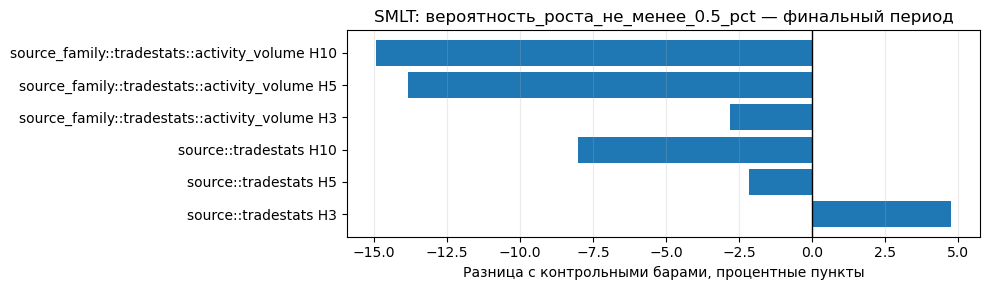

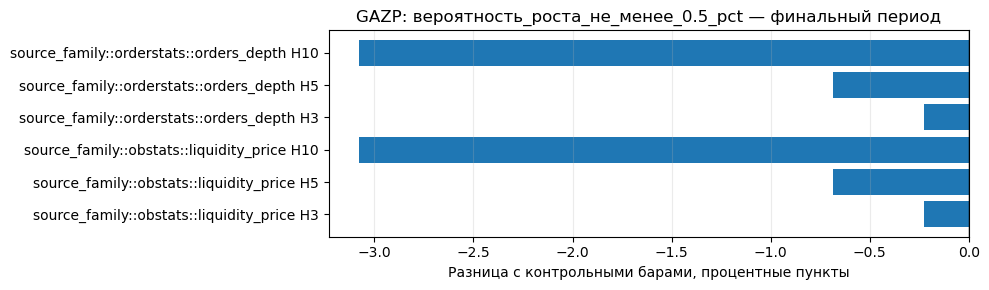

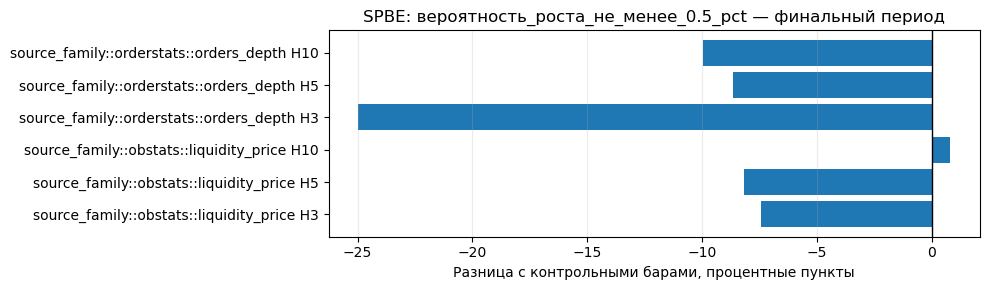

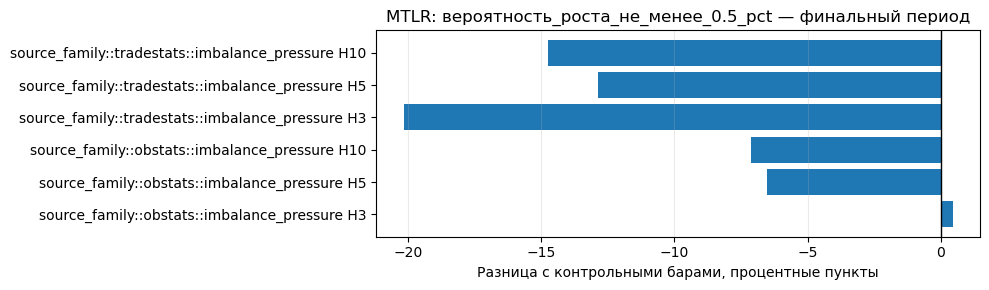

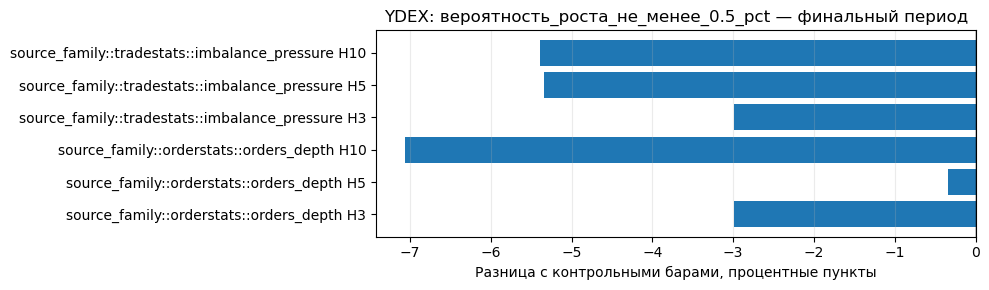

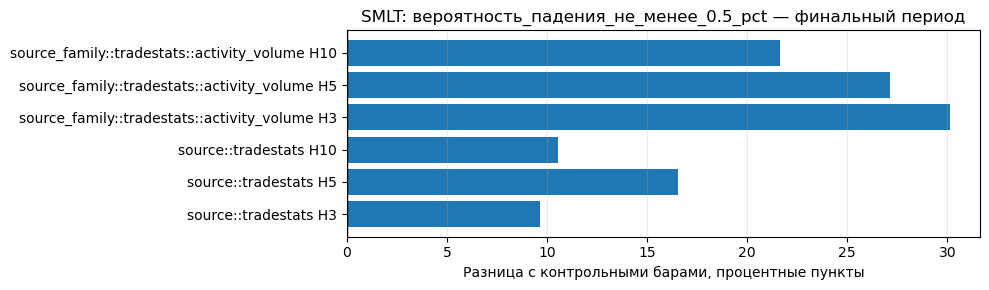

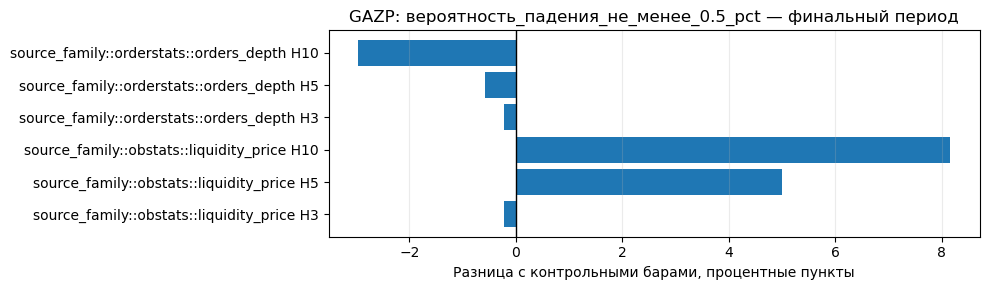

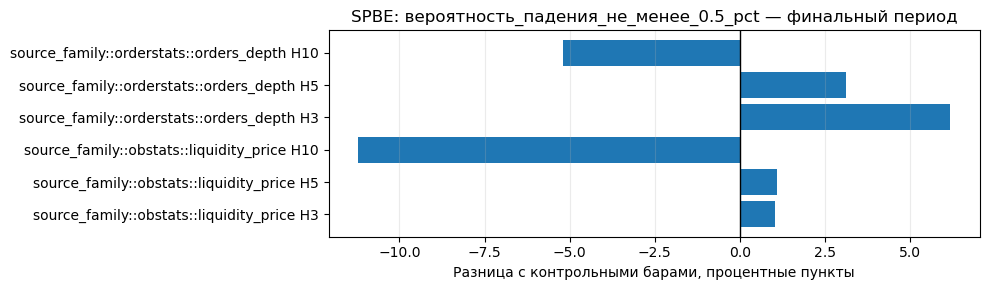

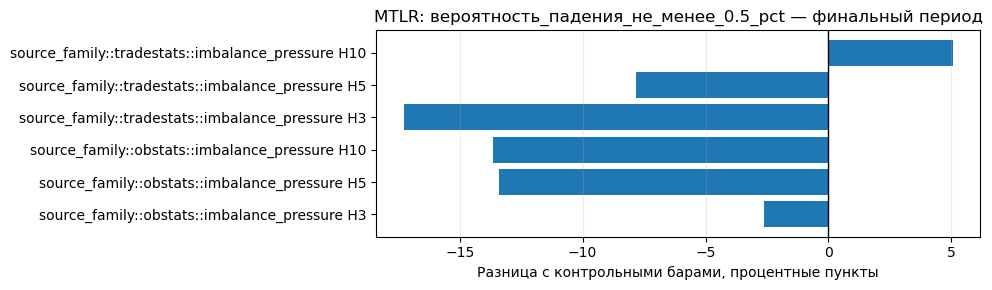

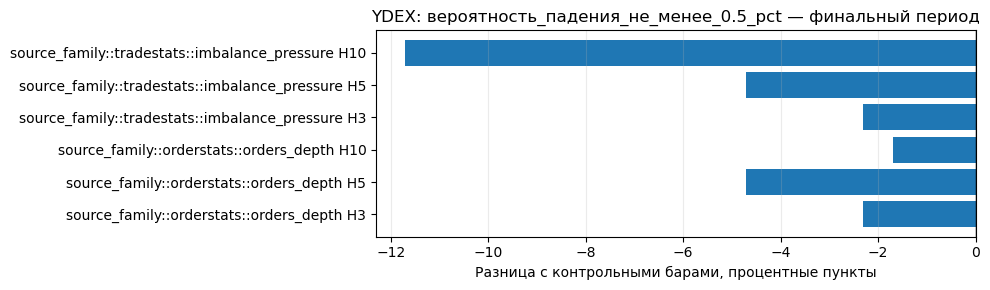

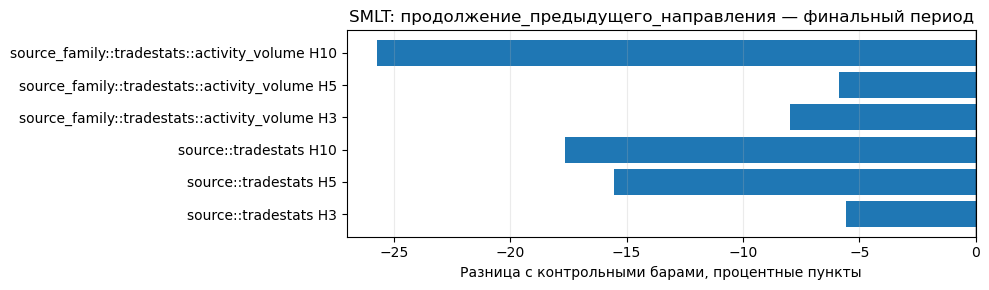

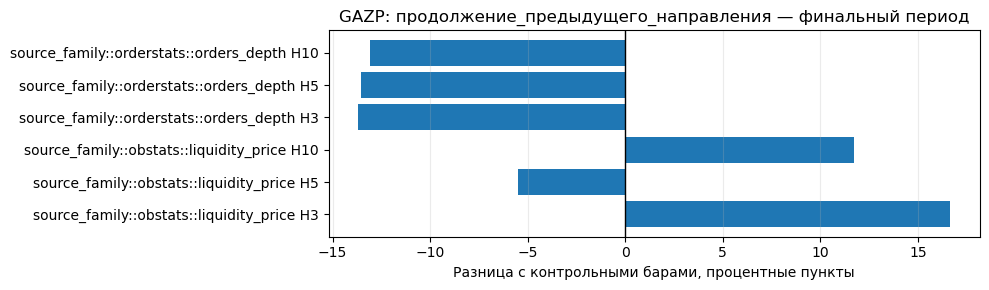

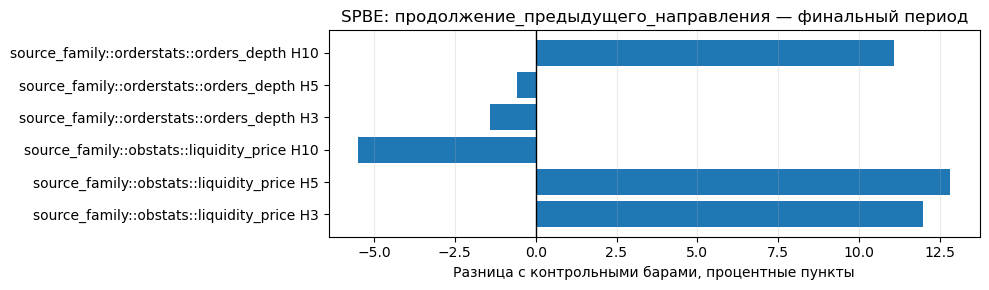

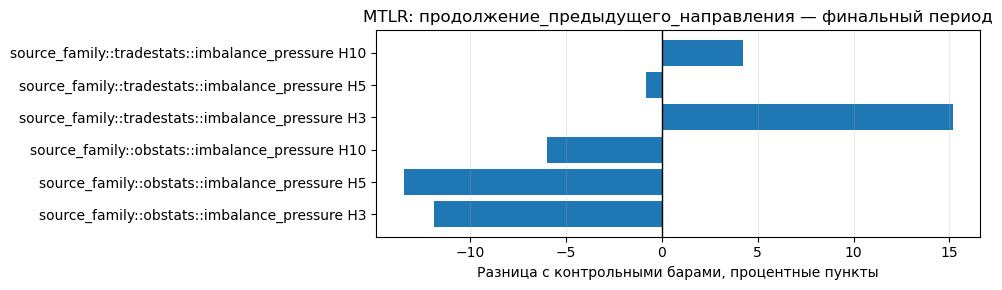

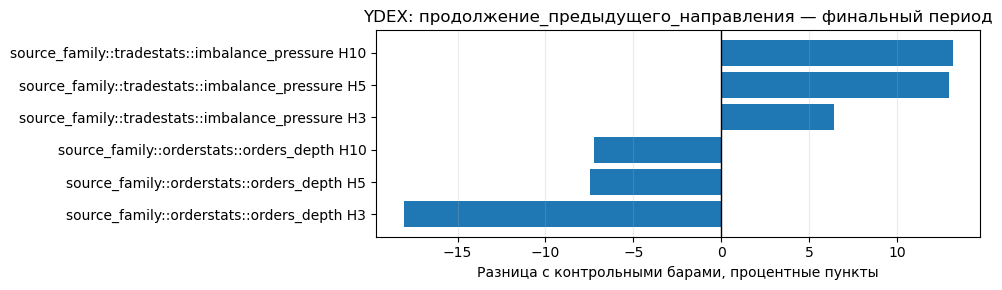

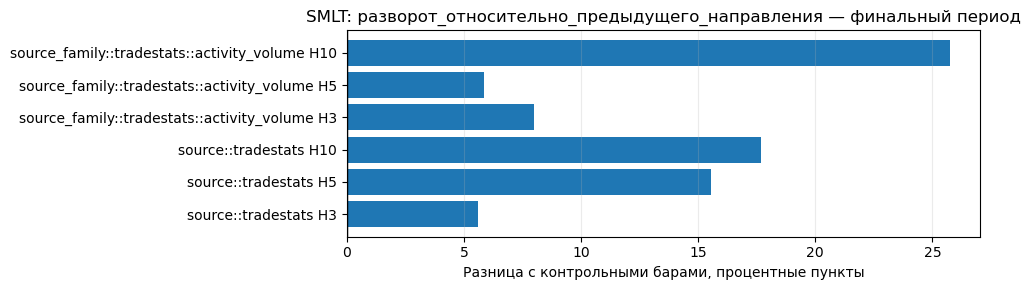

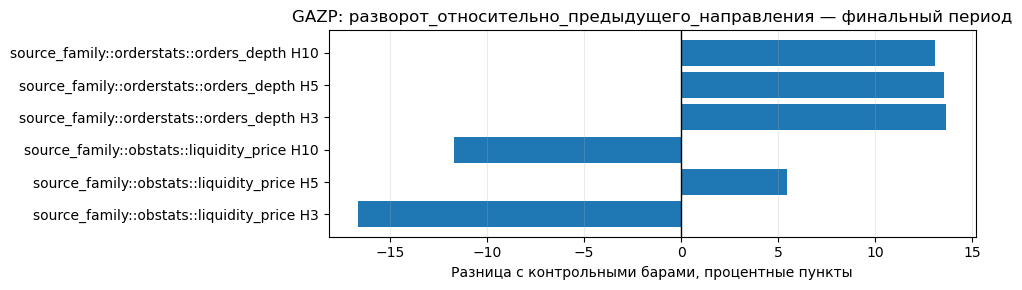

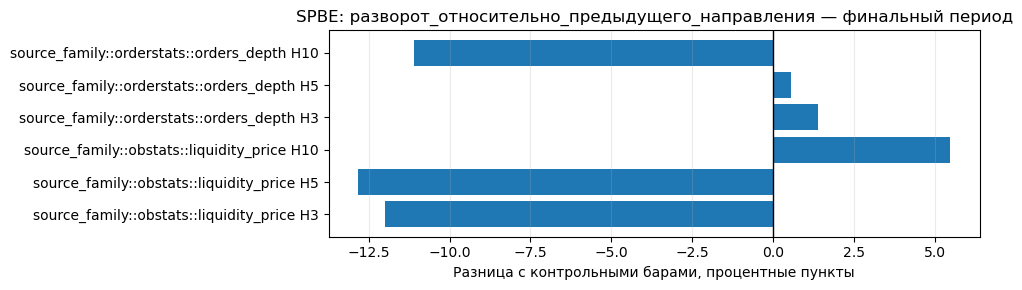

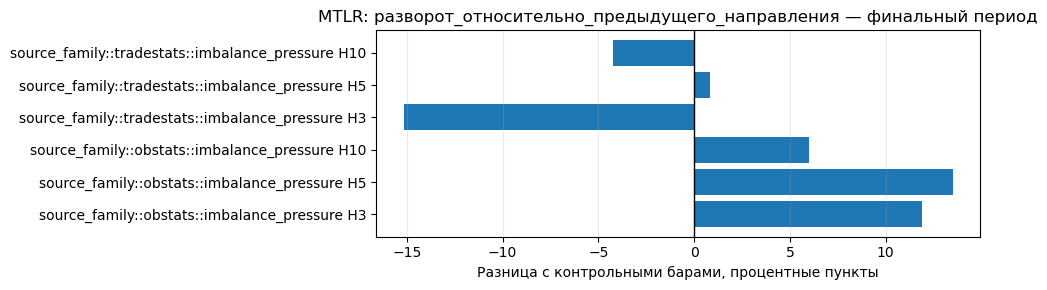

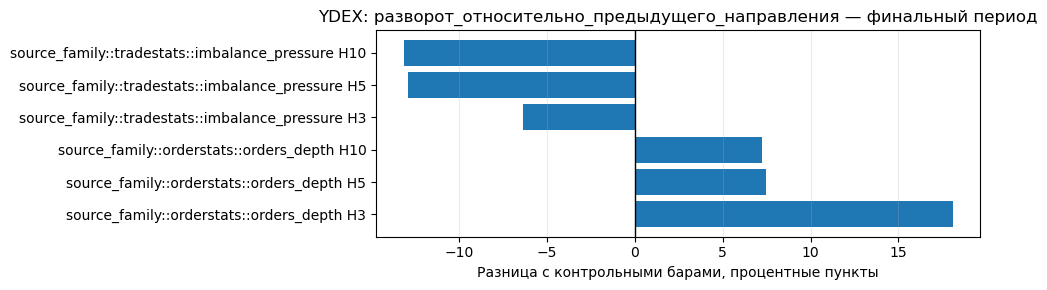

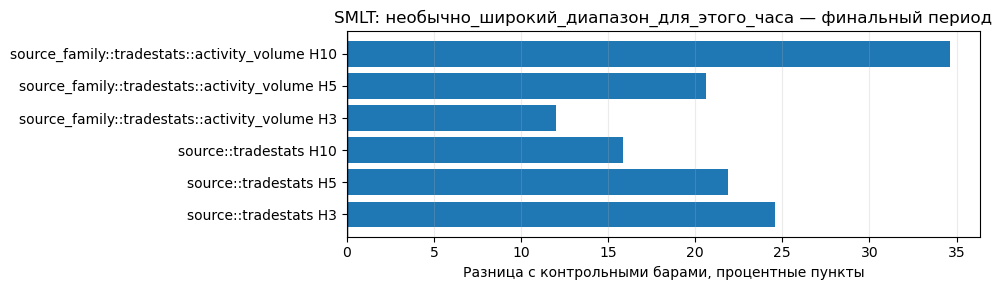

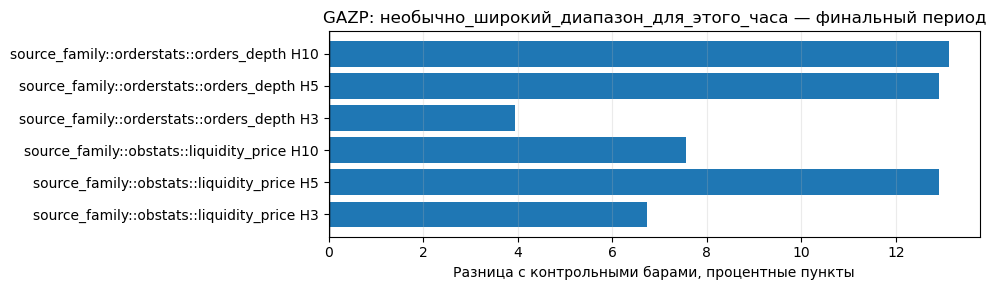

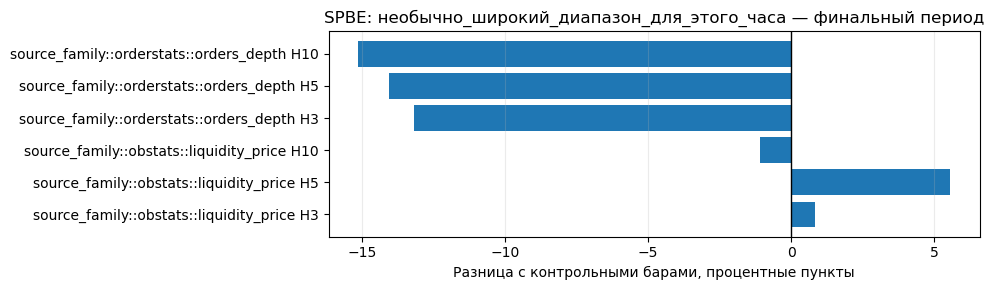

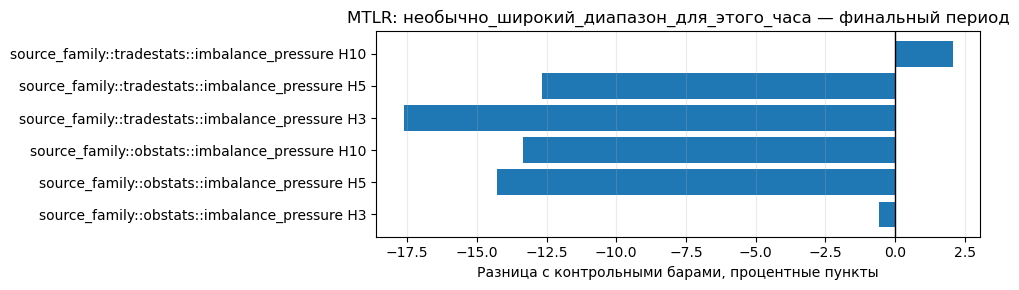

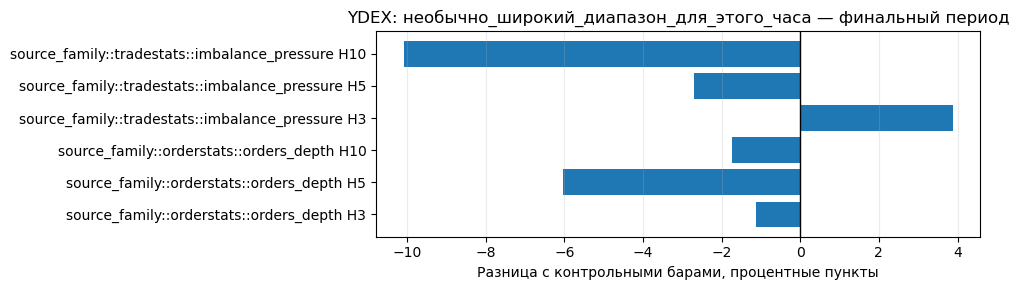

,тикер,группа,порог_аномалии,горизонт_баров,событийных_сделок,средняя_доходность_прокси_после_издержек_pct,медианная_доходность_прокси_после_издержек_pct,средняя_доходность_правила_без_фильтра_pct,разница_средней_доходности_pct,примечание
20,MTLR,source_family::tradestats::imbalance_pressure,0.95,10,13,0.834762,-0.057513,-0.121396,0.956157,"исследовательский прокси, не бэктест базовой с..."
19,MTLR,source_family::tradestats::imbalance_pressure,0.95,5,14,0.321639,-0.048297,-0.187784,0.509422,"исследовательский прокси, не бэктест базовой с..."
18,MTLR,source_family::tradestats::imbalance_pressure,0.95,3,14,0.256284,-0.000247,-0.122699,0.378983,"исследовательский прокси, не бэктест базовой с..."
13,SPBE,source_family::obstats::liquidity_price,0.95,5,18,0.310117,0.208782,-0.031644,0.341761,"исследовательский прокси, не бэктест базовой с..."
17,SPBE,source_family::orderstats::orders_depth,0.95,10,23,0.301003,0.314144,-0.038980,0.339983,"исследовательский прокси, не бэктест базовой с..."
14,SPBE,source_family::obstats::liquidity_price,0.95,10,18,0.278916,-0.196252,-0.038980,0.317896,"исследовательский прокси, не бэктест базовой с..."
26,YDEX,source_family::tradestats::imbalance_pressure,0.99,10,13,-0.038833,-0.037014,-0.084797,0.045964,"исследовательский прокси, не бэктест базовой с..."
12,SPBE,source_family::obstats::liquidity_price,0.95,3,18,-0.019259,-0.021639,-0.063481,0.044221,"исследовательский прокси, не бэктест базовой с..."
8,GAZP,source_family::obstats::liquidity_price,0.99,10,18,-0.054255,-0.044058,-0.086951,0.032697,"исследовательский прокси, не бэктест базовой с..."
25,YDEX,source_family::tradestats::imbalance_pressure,0.99,5,13,-0.066066,-0.037259,-0.083006,0.016940,"исследовательский прокси, не бэктест базовой с..."


In [8]:

if not results_df.empty:
    final = results_df[results_df["сегмент"]=="финальный_тест"].copy()
    plot_metrics = [
        "вероятность_роста_не_менее_0.5_pct",
        "вероятность_падения_не_менее_0.5_pct",
        "продолжение_предыдущего_направления",
        "разворот_относительно_предыдущего_направления",
        "необычно_широкий_диапазон_для_этого_часа",
    ]
    for metric in plot_metrics:
        d = final[final["показатель"]==metric]
        if d.empty: continue
        for ticker in d["тикер"].unique():
            x=d[d["тикер"]==ticker].sort_values(["группа","горизонт_баров"])
            labels=[f"{r['группа']} H{int(r['горизонт_баров'])}" for _,r in x.iterrows()]
            fig,ax=plt.subplots(figsize=(10,max(3,0.32*len(x))))
            ax.barh(labels,x["эффект_событие_минус_контроль"])
            ax.axvline(0,color="black",linewidth=1)
            ax.set_title(f"{ticker}: {metric} — финальный период")
            ax.set_xlabel("Разница с контрольными барами, процентные пункты")
            ax.grid(axis="x",alpha=.25)
            plt.tight_layout(); plt.show()
    if not proxy_df.empty:
        display(proxy_df.sort_values("разница_средней_доходности_pct",ascending=False))
else:
    print("Нет результатов: проверь сообщения загрузки/выравнивания данных.")


## 5. Как принять решение по результатам

1. **Направленный сигнал:** эффект роста или падения положительный, устойчив на валидации и финальном периоде, а неопределённость приемлема.
2. **Индикатор активности:** вероятность движения в любую сторону и/или необычно широкого диапазона растёт, но направление не предсказывается.
3. **Фильтр спокойного режима:** вероятность движения и широкого диапазона снижается; это может обосновать отключение части входов, но нужно проверить на реальных сигналах базовой стратегии.
4. **Сигнал продолжения/разворота:** отдельно подтверждается соответствующим показателем; один отрицательный результат продолжения недостаточен.
5. **Правило торговли:** CSV `SC_07_rule_proxy_final_test.csv` — только грубая проверка правила «направление предыдущего бара + аномалия». Она не заменяет тест настоящей стратегии, не учитывает проскальзывание, порядок достижения стопа/цели внутри бара и перекрытие позиций.

**Ключевой следующий шаг после SC_07:** подключить фактические сигналы выбранной базовой стратегии JERICHON к уже зафиксированным правилам режима и проверить прирост результата после реальных издержек. Не выбирать группы заново по финальному периоду.